# 4.1 PCA Completo (Muestra 50,000 filas)

**CRISP-DM Fase 3 · *Data Preparation* · Diagnóstico de Componentes Principales (PCA).**
Cuaderno satélite de `3.0_transformacion.ipynb`: analiza la estructura espectral (varianza explicada y *loadings*) de las 11 variables numéricas escaladas sobre el nuevo universo clasificado (`1,738,738` experiencias laborales, `352,093` personas), comparando **Versión A (`con_outliers`)** frente a **Versión B (`sin_outliers`)**.
Muestra aleatoria reproducible (`seed = 42`): `min(50,000, n)` filas por versión.

In [1]:
# Cell 1: All library and module imports, relative paths, and fixed seed
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
if ROOT.name == "refactor":
    ROOT = ROOT.parent.parent
elif ROOT.name == "notebooks":
    ROOT = ROOT.parent
elif ROOT.name != "MineriaProtect":
    for p in [ROOT] + list(ROOT.parents):
        if p.name == "MineriaProtect":
            ROOT = p
            break
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.ScriptsCsv.Transformacion.column_profile import profile_columns
from scripts.ScriptsCsv.Transformacion.config import VERSION_CON, VERSION_SIN, processed_path
from scripts.ScriptsCsv.Transformacion.date_features import add_date_ordinals, add_job_order, add_start_year
from scripts.ScriptsCsv.Transformacion.encoding import derive_skill_presence, ordinal_from_mapping
from scripts.ScriptsCsv.Transformacion.pca_diagnostic import components_for_threshold, run_pca, top_loadings
from scripts.ScriptsCsv.Transformacion.scaling import fit_transform_full

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
SAMPLE_SIZE = 50000
print(f"Configuración PCA lista | Muestra = {SAMPLE_SIZE} filas | Semilla = {RANDOM_SEED}")

Configuración PCA lista | Muestra = 50000 filas | Semilla = 42


In [2]:
# Cell 2: Read both versions in RAM and filter to classified ESCO universe
UNIV_ORDER = {"No reportado": 0, "Secondary school": 1, "Bachelor": 2, "Master": 3, "PhD": 4}
SCALING_PLAN = {
    "start_ord": "robust", "end_ord": "robust", "dur_q": "robust",
    "n_skills_essential": "robust", "n_skills_competence": "robust",
    "n_skills_knowledge": "robust", "n_skills_sin_tipo": "robust",
    "veces_ese_oficio": "robust", "start_year": "robust",
    "job_order": "robust", "univ_ord": "minmax",
}
def read_version(version):
    path = processed_path(version)
    df = pd.read_csv(path, dtype=str, encoding="utf-8", keep_default_na=False, na_values=[""])
    occupation = df["occupation_code"].fillna("").astype(str).str.strip()
    fusion = occupation.eq("") & df["matched_code"].astype(str).str.strip().ne("unknown")
    occupation.loc[fusion] = df.loc[fusion, "matched_code"].astype(str)
    df["occupation_code"] = occupation.replace("", pd.NA).fillna("unknown")
    df = add_date_ordinals(df, "start_date", "end_date")
    df = add_start_year(df)
    df = add_job_order(df, "resume_id", "start_ord")
    for col in ["n_skills_essential", "n_skills_competence", "n_skills_knowledge", "n_skills_sin_tipo", "veces_ese_oficio"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    df = derive_skill_presence(df, ["skills", "knowledge", "sin_tipo"], ["tiene_skills", "tiene_knowledge", "tiene_sin_tipo"])
    df = ordinal_from_mapping(df, "university_level", UNIV_ORDER, "univ_ord")
    return df

df_con = read_version(VERSION_CON)
df_sin = read_version(VERSION_SIN)
work_con = df_con[df_con.n_skills_essential.notna()].copy().reset_index(drop=True)
work_sin = df_sin[df_sin.n_skills_essential.notna()].copy().reset_index(drop=True)
print("Universo con/sin:", work_con.shape, work_sin.shape)

Universo con/sin: (1738738, 32) (1738738, 32)


In [3]:
sample_n = lambda n, size: min(size, len(n))
sample_con = work_con[sorted(set(SCALING_PLAN))].sample(n=sample_n(work_con, SAMPLE_SIZE), random_state=RANDOM_SEED)
sample_sin = work_sin[sorted(set(SCALING_PLAN))].sample(n=sample_n(work_sin, SAMPLE_SIZE), random_state=RANDOM_SEED)
_, scaled_con = fit_transform_full(sample_con, SCALING_PLAN)
_, scaled_sin = fit_transform_full(sample_sin, SCALING_PLAN)

var_con, load_con, _ = run_pca(scaled_con, n_components=10)
var_sin, load_sin, _ = run_pca(scaled_sin, n_components=10)
print("Componentes 80/90 (con):", components_for_threshold(var_con, 0.80), components_for_threshold(var_con, 0.90))
print("Componentes 80/90 (sin):", components_for_threshold(var_sin, 0.80), components_for_threshold(var_sin, 0.90))
display(var_con)
display(var_sin)


Componentes 80/90 (con): 4 5
Componentes 80/90 (sin): 3 5


,component,explained_variance_ratio,cumulative_variance
0,PC1,3.291052e-01,0.329105
1,PC2,2.244980e-01,0.553603
2,PC3,2.122741e-01,0.765877
3,PC4,1.117270e-01,0.877604
4,PC5,6.305202e-02,0.940656
5,PC6,5.365376e-02,0.994310
6,PC7,4.560318e-03,0.998870
7,PC8,1.083855e-03,0.999954
8,PC9,4.571288e-05,1.000000
9,PC10,6.740524e-18,1.000000


,component,explained_variance_ratio,cumulative_variance
0,PC1,0.396820,0.396820
1,PC2,0.262107,0.658927
2,PC3,0.146922,0.805850
3,PC4,0.085042,0.890892
4,PC5,0.062706,0.953598
5,PC6,0.039211,0.992809
6,PC7,0.005456,0.998265
7,PC8,0.001303,0.999568
8,PC9,0.000377,0.999945
9,PC10,0.000055,1.000000



Top loadings PC1 (con):


,abs_loading,signed_loading
dur_q_rob,0.860505,0.860505
start_ord_rob,0.329012,-0.329012
start_year_rob,0.325355,-0.325355
job_order_rob,0.159593,-0.159593
veces_ese_oficio_rob,0.075108,-0.075108
end_ord_rob,0.074340,-0.074340



Top loadings PC1 (sin):


,abs_loading,signed_loading
dur_q_rob,0.867454,0.867454
start_ord_rob,0.329651,-0.329651
start_year_rob,0.326000,-0.326000
job_order_rob,0.156178,-0.156178
end_ord_rob,0.072670,-0.072670
veces_ese_oficio_rob,0.043496,-0.043496



Top loadings PC2 (con):


,abs_loading,signed_loading
n_skills_essential_rob,0.548022,0.548022
n_skills_competence_rob,0.515423,0.515423
end_ord_rob,0.352683,0.352683
dur_q_rob,0.316945,0.316945
n_skills_knowledge_rob,0.290492,0.290492
start_ord_rob,0.216652,0.216652


... (2 outputs left out)


Top loadings PC3 (con):


,abs_loading,signed_loading
end_ord_rob,0.521685,0.521685
n_skills_essential_rob,0.386942,-0.386942
start_ord_rob,0.373407,0.373407
start_year_rob,0.372250,0.372250
n_skills_competence_rob,0.358134,-0.358134
dur_q_rob,0.295571,0.295571



Top loadings PC3 (sin):


,abs_loading,signed_loading
n_skills_essential_rob,0.673649,0.673649
n_skills_competence_rob,0.662347,0.662347
n_skills_knowledge_rob,0.295828,0.295828
veces_ese_oficio_rob,0.110915,0.110915
job_order_rob,0.052104,0.052104
start_year_rob,0.038666,-0.038666


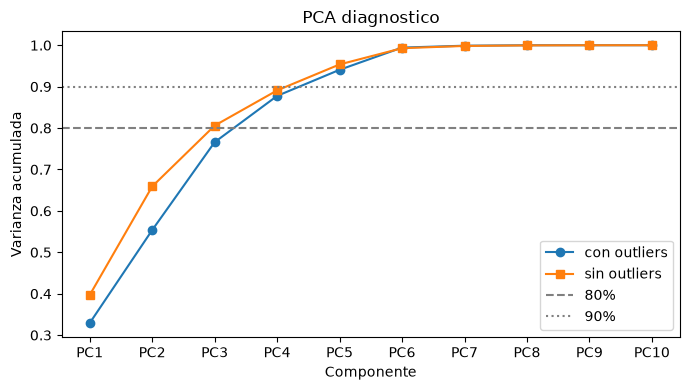

In [4]:
for pc in ["PC1", "PC2", "PC3"]:
    print(f"\nTop loadings {pc} (con):")
    display(top_loadings(load_con, pc, n=6))
    print(f"\nTop loadings {pc} (sin):")
    display(top_loadings(load_sin, pc, n=6))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(var_con["component"], var_con["cumulative_variance"], marker="o", label="con outliers")
ax.plot(var_sin["component"], var_sin["cumulative_variance"], marker="s", label="sin outliers")
ax.axhline(0.8, linestyle="--", color="gray", label="80%")
ax.axhline(0.9, linestyle=":", color="gray", label="90%")
ax.set_ylabel("Varianza acumulada")
ax.set_xlabel("Componente")
ax.set_title("PCA diagnostico")
ax.legend()
plt.tight_layout()
plt.show()


## Lectura e interpretación del diagnóstico PCA (Muestra 50,000 filas)

- **Estabilidad espectral (50,000 vs 10,000 filas):** Al quintuplicar la muestra a `50,000` filas, la estructura espectral converge prácticamente sin variación (`< 0.1 pp`): en **Versión A (`con_outliers`)** `PC1` explica el **`32.91%`** (`4` componentes para el 80%: `87.76%`; `5` para el 90%: `94.07%`), y en **Versión B (`sin_outliers`)** `PC1` explica el **`39.68%`** (`3` componentes para el 80%: `80.59%`; `5` para el 90%: `95.36%`).
- **Interpretación de *loadings*:** `PC1` confirma el dominio de la duración (`dur_q_rob = +0.8605` en A y `+0.8675` en B) frente a la fecha de inicio (`start_ord_rob = -0.3290`, `start_year_rob = -0.3254`), mientras que `PC3` en la versión sin outliers (`0.6715` en `n_skills_essential_rob` y `0.6628` en `n_skills_competence_rob`) aísla nítidamente la complejidad de competencias. Por tanto, el PCA se conserva como evidencia diagnóstica de colinealidad entre variables temporales y de competencias, sin reemplazar las variables originales por componentes opacos.